In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Load the same clustering data as Mining.ipynb
cl = pd.read_csv("prepared_clustering.csv")
labels = ["id", "neighbourhood_group_cleansed", "license_status", "short_stay"]
X = cl.drop(columns=labels)

# Join back real values (dollars, nights) to describe the clusters
clean = pd.read_csv("listings_clean.csv")
info = cl[labels].merge(clean[["id", "price", "room_type", "property_type", "minimum_nights",
                               "number_of_reviews", "calculated_host_listings_count"]], on="id")
info["is_hotel"] = info["property_type"].str.contains("hotel", case=False, na=False)

def profile(k):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    info["cluster"] = km.labels_
    return info.groupby("cluster").agg(
        listings=("id", "count"),
        median_price=("price", "median"),
        pct_entire_home=("room_type", lambda s: (s == "Entire home/apt").mean() * 100),
        pct_hotel=("is_hotel", lambda s: s.mean() * 100),
        pct_short_stay=("short_stay", lambda s: s.mean() * 100),
        median_reviews=("number_of_reviews", "median"),
        median_host_listings=("calculated_host_listings_count", "median"),
    ).round(1)

print("k = 3")
display(profile(3))

k = 3


,listings,median_price,pct_entire_home,pct_hotel,pct_short_stay,median_reviews,median_host_listings
cluster,,,,,,,
0,2577,363.0,88.4,5.1,18.7,4.0,2.0
1,12168,130.0,54.7,0.8,0.8,3.0,3.0
2,4651,359.0,25.2,35.1,98.0,50.0,3.0


k3_name,All monthly,All short stays,Pricey whole homes
k6_name,,,
Big-operator apartments,93.2,0.5,6.3
"Cheap rooms, never reviewed",98.1,0.1,1.7
Hotel rooms,11.3,82.6,6.1
"Monthly homes, small hosts",91.1,1.2,7.7
Popular short stays,0.0,98.9,1.1
Pricey whole homes,0.0,0.1,99.9


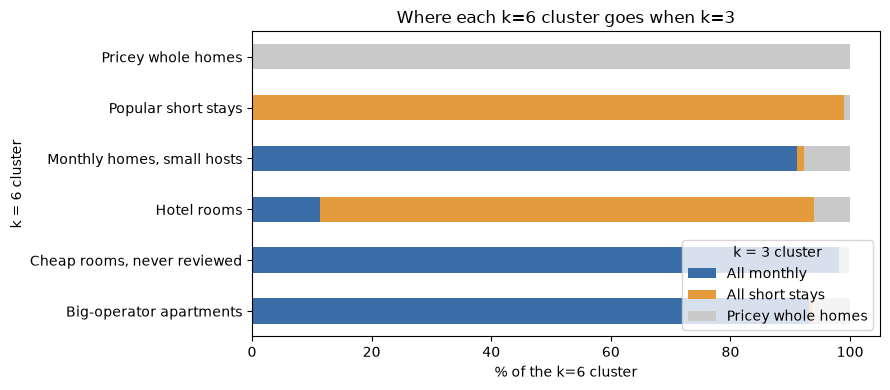

In [3]:
# Sensitivity 2: where does each k=6 cluster go when k=3?
names6 = {0: "Monthly homes, small hosts", 1: "Popular short stays", 2: "Cheap rooms, never reviewed",
          3: "Pricey whole homes", 4: "Hotel rooms", 5: "Big-operator apartments"}
names3 = {0: "Pricey whole homes", 1: "All monthly", 2: "All short stays"}

info["k6"] = KMeans(n_clusters=6, n_init=10, random_state=42).fit(X).labels_
info["k3"] = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X).labels_
info["k6_name"] = info["k6"].map(names6)
info["k3_name"] = info["k3"].map(names3)

move = pd.crosstab(info["k6_name"], info["k3_name"], normalize="index").mul(100).round(1)
display(move)

move.plot(kind="barh", stacked=True, figsize=(9, 4), color=["#3B6EA8", "#E39B3B", "#C9C9C9"])
plt.xlabel("% of the k=6 cluster"); plt.ylabel("k = 6 cluster")
plt.title("Where each k=6 cluster goes when k=3")
plt.legend(title="k = 3 cluster", loc="lower right")
plt.tight_layout(); plt.savefig("sensitivity_k3_vs_k6.png"); plt.show()